# 01 EDA and balance check

**Stage 1 / G2.** Explore the development sample, verify treatment randomization across the 10 kept features, and estimate average treatment effects on both development and holdout splits.

**Inputs:** `data/criteo.parquet`, `results/kept_features.json`

**Outputs:**
- `results/balance_table_1m.csv`
- `results/balance_smd_1m.png`
- `results/ate_visit_conversion.csv`

In [1]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from uplift.data import TREATMENT, OUTCOMES, make_splits, take, treated_share_ok

results_dir = ROOT / "results"
results_dir.mkdir(exist_ok=True)

# 1. Load parquet and build deterministic development (1M) and holdout (2M) splits
parquet_path = ROOT / "data" / "criteo.parquet"
df = pd.read_parquet(parquet_path)
test_ids, pool_ids = make_splits(len(df))

dev = take(df, pool_ids[:1_000_000])
hold = take(df, test_ids)
del df

assert treated_share_ok(dev), "Unexpected treated share in development sample!"
assert treated_share_ok(hold), "Unexpected treated share in holdout sample!"

# 2. Load the 10 kept features from JSON
with open(results_dir / "kept_features.json", "r", encoding="utf-8") as f:
    kept_features = json.load(f)

print(f"Dev shape: {dev.shape} | Treated share: {dev[TREATMENT].mean():.4f}")
print(f"Holdout shape: {hold.shape} | Treated share: {hold[TREATMENT].mean():.4f}")
print(f"Kept features ({len(kept_features)}): {kept_features}")
print("Missing values (dev):", dev[kept_features + [TREATMENT] + OUTCOMES].isna().sum().to_dict())
display(dev[kept_features].describe().T[["mean", "std", "min", "50%", "max"]])

Dev shape: (1000000, 16) | Treated share: 0.8503
Holdout shape: (2000000, 16) | Treated share: 0.8497
Kept features (10): ['f0', 'f2', 'f3', 'f4', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11']
Missing values (dev): {'f0': 0, 'f2': 0, 'f3': 0, 'f4': 0, 'f6': 0, 'f7': 0, 'f8': 0, 'f9': 0, 'f10': 0, 'f11': 0, 'treatment': 0, 'visit': 0, 'conversion': 0}


,mean,std,min,50%,max
f0,19.620731,5.378438,12.616364,21.924356,26.745255
f2,8.446327,0.299201,8.214383,8.214383,9.051962
f3,4.178294,1.338535,-6.476717,4.679882,4.679882
f4,10.338867,0.342984,10.280525,10.280525,21.123508
f6,-4.156839,4.583096,-28.153719,-2.411115,0.294443
f7,5.102538,1.207454,4.833815,4.833815,11.998397
f8,3.933614,0.056628,3.636244,3.971858,3.971858
f9,16.025267,7.011258,13.190056,13.190056,66.954887
f10,5.333594,0.168698,5.300375,5.300375,6.473917
f11,-0.170970,0.022835,-1.383941,-0.168679,-0.168679


,feature,mean_treated,mean_control,SMD,abs_SMD
0,f3,4.167905,4.237304,-0.053585,0.053585
1,f6,-4.185396,-3.994643,-0.042196,0.042196
2,f9,16.054279,15.860481,0.028039,0.028039
3,f8,3.933408,3.934786,-0.024556,0.024556
4,f7,5.106296,5.081192,0.021079,0.021079
5,f10,5.333938,5.331638,0.013789,0.013789
6,f4,10.339544,10.335027,0.013378,0.013378
7,f0,19.613384,19.662476,-0.009120,0.009120
8,f11,-0.170999,-0.170808,-0.008471,0.008471
9,f2,8.446228,8.446890,-0.002209,0.002209


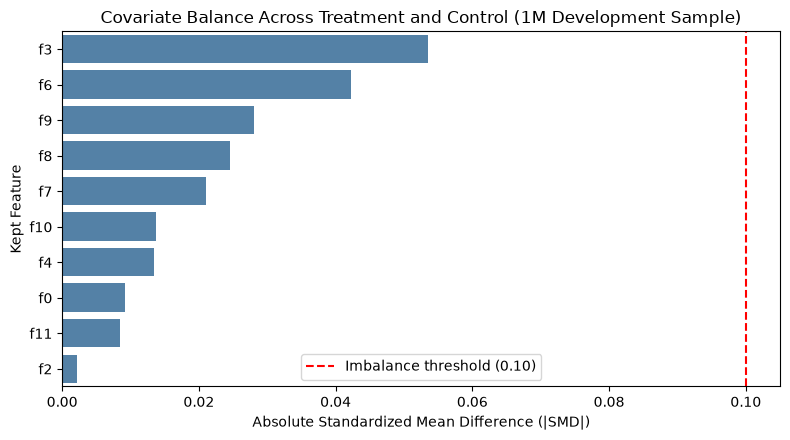

In [2]:
# 3. Randomization balance check (Standardized Mean Difference) on 1M dev sample
t_dev = dev[dev[TREATMENT] == 1]
c_dev = dev[dev[TREATMENT] == 0]

balance_rows = []
for col in kept_features:
    mt, mc = float(t_dev[col].mean()), float(c_dev[col].mean())
    vt, vc = float(t_dev[col].var(ddof=1)), float(c_dev[col].var(ddof=1))
    smd = (mt - mc) / np.sqrt((vt + vc) / 2.0)
    balance_rows.append({
        "feature": col,
        "mean_treated": mt,
        "mean_control": mc,
        "SMD": smd,
        "abs_SMD": abs(smd),
    })

balance_df = pd.DataFrame(balance_rows).sort_values("abs_SMD", ascending=False).reset_index(drop=True)
display(balance_df)
balance_df.to_csv(results_dir / "balance_table_1m.csv", index=False)

# Horizontal bar chart of absolute standardized mean difference
plt.figure(figsize=(8, 4.5))
sns.barplot(data=balance_df, x="abs_SMD", y="feature", color="steelblue")
plt.axvline(0.1, color="red", linestyle="--", label="Imbalance threshold (0.10)")
plt.xlabel("Absolute Standardized Mean Difference (|SMD|)")
plt.ylabel("Kept Feature")
plt.title("Covariate Balance Across Treatment and Control (1M Development Sample)")
plt.legend()
plt.tight_layout()
plt.savefig(results_dir / "balance_smd_1m.png", dpi=150)
plt.show()

In [3]:
# 4. Average treatment effect (ATE) with 95% CI across dev and holdout samples
ate_rows = []
for sample_name, sample_df in [("dev", dev), ("hold", hold)]:
    t_sub = sample_df[sample_df[TREATMENT] == 1]
    c_sub = sample_df[sample_df[TREATMENT] == 0]
    n1, n0 = len(t_sub), len(c_sub)
    for outcome in OUTCOMES:
        p1 = float(t_sub[outcome].mean())
        p0 = float(c_sub[outcome].mean())
        ate = p1 - p0
        se = float(np.sqrt(p1 * (1.0 - p1) / n1 + p0 * (1.0 - p0) / n0))
        ci_lo = ate - 1.96 * se
        ci_hi = ate + 1.96 * se
        ate_rows.append({
            "sample": sample_name,
            "outcome": outcome,
            "n_treated": n1,
            "n_control": n0,
            "rate_treated": p1,
            "rate_control": p0,
            "ate": ate,
            "ci_lo": ci_lo,
            "ci_hi": ci_hi,
        })

ate_df = pd.DataFrame(ate_rows)
display(ate_df)
ate_df.to_csv(results_dir / "ate_visit_conversion.csv", index=False)

,sample,outcome,n_treated,n_control,rate_treated,rate_control,ate,ci_lo,ci_hi
0,dev,visit,850292,149708,0.048864,0.037587,0.011278,0.010211,0.012345
1,dev,conversion,850292,149708,0.003126,0.001997,0.001129,0.000873,0.001384
2,hold,visit,1699321,300679,0.048501,0.038549,0.009952,0.009192,0.010712
3,hold,conversion,1699321,300679,0.003129,0.001956,0.001174,0.000995,0.001353


In [4]:
# 5. Dynamic markdown summary derived directly from balance_df
max_abs_smd = float(balance_df["abs_SMD"].max())
max_feat = balance_df.loc[balance_df["abs_SMD"].idxmax(), "feature"]
below_thresh = max_abs_smd < 0.1

if below_thresh:
    summary_text = (
        f"The largest absolute standardized mean difference across the ten kept features is "
        f"{max_abs_smd:.4f} (on `{max_feat}`), which is below the 0.1 threshold and confirms "
        f"that treatment and control covariates are well balanced by random assignment."
    )
else:
    summary_text = (
        f"The largest absolute standardized mean difference across the ten kept features is "
        f"{max_abs_smd:.4f} (on `{max_feat}`), which is at or above the 0.1 threshold and "
        f"indicates notable covariate imbalance between treatment and control groups."
    )

display(Markdown(summary_text))

The largest absolute standardized mean difference across the ten kept features is 0.0536 (on `f3`), which is below the 0.1 threshold and confirms that treatment and control covariates are well balanced by random assignment.